In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_excel("Data/Flight_Fare.xlsx")

In [3]:
df.head()

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
0,IndiGo,24/03/2019,Banglore,New Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882
3,IndiGo,12/05/2019,Kolkata,Banglore,CCU → NAG → BLR,18:05,23:30,5h 25m,1 stop,No info,6218
4,IndiGo,01/03/2019,Banglore,New Delhi,BLR → NAG → DEL,16:50,21:35,4h 45m,1 stop,No info,13302


In [4]:
df.describe()

,Price
count,10683.000000
mean,9087.064121
std,4611.359167
min,1759.000000
25%,5277.000000
50%,8372.000000
75%,12373.000000
max,79512.000000


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10683 entries, 0 to 10682
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Airline          10683 non-null  str  
 1   Date_of_Journey  10683 non-null  str  
 2   Source           10683 non-null  str  
 3   Destination      10683 non-null  str  
 4   Route            10682 non-null  str  
 5   Dep_Time         10683 non-null  str  
 6   Arrival_Time     10683 non-null  str  
 7   Duration         10683 non-null  str  
 8   Total_Stops      10682 non-null  str  
 9   Additional_Info  10683 non-null  str  
 10  Price            10683 non-null  int64
dtypes: int64(1), str(10)
memory usage: 918.2 KB


In [6]:
df.isnull().sum()

Airline            0
Date_of_Journey    0
Source             0
Destination        0
Route              1
Dep_Time           0
Arrival_Time       0
Duration           0
Total_Stops        1
Additional_Info    0
Price              0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(220)

In [8]:
missing_row = df[df.isnull().any(axis=1)]
missing_row

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
9039,Air India,6/05/2019,Delhi,Cochin,NaN,09:45,09:25 07 May,23h 40m,NaN,No info,7480


In [9]:
df[(df["Airline"]=="Air India") & (df["Source"]== "Delhi") & (df["Destination"]== "Cochin")]

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price
10,Air India,1/06/2019,Delhi,Cochin,DEL → BLR → COK,09:45,23:00,13h 15m,1 stop,No info,8907
15,Air India,3/03/2019,Delhi,Cochin,DEL → AMD → BOM → COK,16:40,19:15 04 Mar,26h 35m,2 stops,No info,14011
18,Air India,12/06/2019,Delhi,Cochin,DEL → CCU → BOM → COK,20:15,19:15 13 Jun,23h,2 stops,No info,13381
61,Air India,3/04/2019,Delhi,Cochin,DEL → MAA → COK,06:05,09:25 04 Apr,27h 20m,1 stop,No info,5117
68,Air India,21/05/2019,Delhi,Cochin,DEL → BHO → BOM → COK,05:55,19:15,13h 20m,2 stops,No info,10861
...,...,...,...,...,...,...,...,...,...,...,...
10648,Air India,1/06/2019,Delhi,Cochin,DEL → CCU → BOM → COK,16:55,19:15 02 Jun,26h 20m,2 stops,No info,13801
10652,Air India,9/03/2019,Delhi,Cochin,DEL → TRV → COK,05:15,06:50 10 Mar,25h 35m,1 stop,No info,9790
10661,Air India,9/05/2019,Delhi,Cochin,DEL → BOM → COK,13:00,19:15,6h 15m,1 stop,No info,8372
10669,Air India,15/06/2019,Delhi,Cochin,DEL → BOM → COK,08:00,19:15,11h 15m,1 stop,No info,9929


In [10]:
df[
    (df["Airline"] == "Air India") &
    (df["Source"] == "Delhi") &
    (df["Destination"] == "Cochin")
][["Route", "Total_Stops"]].value_counts(dropna=False)

Route                        Total_Stops
DEL → BOM → COK              1 stop         117
DEL → MAA → COK              1 stop          77
DEL → COK                    non-stop        75
DEL → BLR → COK              1 stop          73
DEL → AMD → BOM → COK        2 stops         64
DEL → GOI → BOM → COK        2 stops         58
DEL → HYD → BOM → COK        2 stops         56
DEL → HYD → MAA → COK        2 stops         47
DEL → CCU → BOM → COK        2 stops         43
DEL → JAI → BOM → COK        2 stops         33
DEL → BHO → BOM → COK        2 stops         21
DEL → RPR → NAG → BOM → COK  3 stops         17
DEL → LKO → BOM → COK        2 stops         16
DEL → JDH → BOM → COK        2 stops         14
DEL → TRV → COK              1 stop          14
DEL → UDR → BOM → COK        2 stops         11
DEL → NAG → BOM → COK        2 stops         10
NaN                          NaN              1
Name: count, dtype: int64

In [11]:
def duration_to_minutes(duration):
    hours = 0
    minutes = 0

    for part in duration.split():
        if "h" in part:
            hours = int(part.replace("h", ""))
        elif "m" in part:
            minutes = int(part.replace("m", ""))

    return hours * 60 + minutes

df["Duration_Minutes"] = df["Duration"].apply(duration_to_minutes)


In [12]:
df[["Duration", "Duration_Minutes"]].head(10)

,Duration,Duration_Minutes
0,2h 50m,170
1,7h 25m,445
2,19h,1140
3,5h 25m,325
4,4h 45m,285
5,2h 25m,145
6,15h 30m,930
7,21h 5m,1265
8,25h 30m,1530
9,7h 50m,470


In [13]:
similar_flights = df[
    (df["Airline"] == "Air India") &
    (df["Source"] == "Delhi") &
    (df["Destination"] == "Cochin") &
    (df["Duration_Minutes"].between(1380, 1440))
]

similar_flights[
    ["Duration", "Duration_Minutes", "Route",
     "Total_Stops", "Price"]
].sort_values("Duration_Minutes")

,Duration,Duration_Minutes,Route,Total_Stops,Price
18,23h,1380,DEL → CCU → BOM → COK,2 stops,13381
1890,23h,1380,DEL → CCU → BOM → COK,2 stops,13591
5318,23h,1380,DEL → CCU → BOM → COK,2 stops,13591
3827,23h,1380,DEL → CCU → BOM → COK,2 stops,13591
5064,23h,1380,DEL → CCU → BOM → COK,2 stops,13591
...,...,...,...,...,...
9440,23h 40m,1420,DEL → MAA → COK,1 stop,8372
9974,23h 40m,1420,DEL → MAA → COK,1 stop,24017
10348,23h 40m,1420,DEL → HYD → MAA → COK,2 stops,9925
9717,23h 40m,1420,DEL → HYD → MAA → COK,2 stops,10975


In [14]:
similar_flights.groupby(
    ["Route", "Total_Stops"],
    dropna=False
).size().sort_values(ascending=False)

Route                  Total_Stops
DEL → AMD → BOM → COK  2 stops        26
DEL → HYD → MAA → COK  2 stops        14
DEL → CCU → BOM → COK  2 stops        13
DEL → MAA → COK        1 stop         12
DEL → BHO → BOM → COK  2 stops         5
DEL → BOM → COK        1 stop          2
NaN                    NaN             1
dtype: int64

In [15]:
clean_df = df.copy()

In [16]:
clean_df = clean_df.dropna(subset=["Route", "Total_Stops"])

In [17]:
df.shape, clean_df.shape

((10683, 12), (10682, 12))

In [18]:
clean_df[["Route", "Total_Stops"]].isna().sum()

Route          0
Total_Stops    0
dtype: int64

In [19]:
clean_df.duplicated().sum()

np.int64(220)

In [20]:
duplicates = clean_df[clean_df.duplicated(keep=False)]

In [21]:
duplicates.sort_values(by=["Airline","Date_of_Journey","Source","Destination"]).head(10)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Duration_Minutes
6321,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135,2345
9848,Air India,01/03/2019,Banglore,New Delhi,BLR → BOM → AMD → DEL,08:50,23:55 02 Mar,39h 5m,2 stops,No info,17135,2345
572,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591,165
8168,Air India,03/03/2019,Banglore,New Delhi,BLR → DEL,21:10,23:55,2h 45m,non-stop,No info,7591,165
1495,Air India,1/04/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,01:20 02 Apr,15h 20m,2 stops,No info,10408,920
9913,Air India,1/04/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,01:20 02 Apr,15h 20m,2 stops,No info,10408,920
3598,Air India,1/05/2019,Kolkata,Banglore,CCU → GAU → DEL → BLR,09:50,08:55 02 May,23h 5m,2 stops,No info,13227,1385
4603,Air India,1/05/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,13:45 02 May,27h 45m,2 stops,No info,15164,1665
5042,Air India,1/05/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,13:45 02 May,27h 45m,2 stops,No info,15164,1665
6377,Air India,1/05/2019,Kolkata,Banglore,CCU → DEL → COK → BLR,10:00,13:45 02 May,27h 45m,2 stops,No info,15164,1665


In [22]:
journey_duplicates = clean_df[
    clean_df.duplicated(
        subset=[
            "Airline",
            "Date_of_Journey",
            "Source",
            "Destination"
        ],
        keep=False
    )
].sort_values(
    ["Airline", "Date_of_Journey", "Source", "Destination"]
)

journey_duplicates.head(20)

,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Duration_Minutes
5964,Air Asia,01/03/2019,Banglore,New Delhi,BLR → DEL,05:50,08:40,2h 50m,non-stop,No info,10715,170
8122,Air Asia,01/03/2019,Banglore,New Delhi,BLR → DEL,23:25,02:10 02 Mar,2h 45m,non-stop,Red-eye flight,10873,165
2266,Air Asia,03/03/2019,Banglore,New Delhi,BLR → DEL,05:50,08:40,2h 50m,non-stop,No info,7074,170
2773,Air Asia,03/03/2019,Banglore,New Delhi,BLR → DEL,05:50,08:40,2h 50m,non-stop,No info,7652,170
4851,Air Asia,03/03/2019,Banglore,New Delhi,BLR → DEL,23:25,02:10 04 Mar,2h 45m,non-stop,No info,6135,165
9107,Air Asia,03/03/2019,Banglore,New Delhi,BLR → DEL,23:25,02:10 07 Mar,2h 45m,non-stop,No info,6477,165
1459,Air Asia,09/03/2019,Banglore,New Delhi,BLR → DEL,05:50,08:40,2h 50m,non-stop,No info,4284,170
2105,Air Asia,09/03/2019,Banglore,New Delhi,BLR → DEL,23:25,02:10 10 Mar,2h 45m,non-stop,No info,5615,165
5601,Air Asia,09/03/2019,Banglore,New Delhi,BLR → DEL,23:25,02:10 13 Mar,2h 45m,non-stop,No info,4482,165
7489,Air Asia,09/03/2019,Banglore,New Delhi,BLR → DEL,05:50,08:40,2h 50m,non-stop,No info,7652,170


In [23]:
original_columns = df.columns.tolist()

exact_duplicates = clean_df[
    clean_df.duplicated(
        subset=original_columns,
        keep=False
    )
]

print("Rows belonging to exact duplicate groups:",
      len(exact_duplicates))

print("Extra duplicate rows to remove:",
      clean_df.duplicated(
          subset=original_columns
      ).sum())

Rows belonging to exact duplicate groups: 415
Extra duplicate rows to remove: 220


In [24]:
final_df = clean_df.drop_duplicates(
    subset=original_columns,
    keep="first"
).copy()

print("Shape before:", clean_df.shape)
print("Shape after:", final_df.shape)
print("Duplicates remaining:",
      final_df.duplicated(subset=original_columns).sum())
print("Missing values remaining:", final_df.isnull().sum().sum())


Shape before: (10682, 12)
Shape after: (10462, 12)
Duplicates remaining: 0
Missing values remaining: 0


In [25]:
final_df.info()

<class 'pandas.DataFrame'>
Index: 10462 entries, 0 to 10682
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Airline           10462 non-null  str  
 1   Date_of_Journey   10462 non-null  str  
 2   Source            10462 non-null  str  
 3   Destination       10462 non-null  str  
 4   Route             10462 non-null  str  
 5   Dep_Time          10462 non-null  str  
 6   Arrival_Time      10462 non-null  str  
 7   Duration          10462 non-null  str  
 8   Total_Stops       10462 non-null  str  
 9   Additional_Info   10462 non-null  str  
 10  Price             10462 non-null  int64
 11  Duration_Minutes  10462 non-null  int64
dtypes: int64(2), str(10)
memory usage: 1.0 MB


In [26]:
final_df["Total_Stops"].value_counts()

Total_Stops
1 stop      5625
non-stop    3475
2 stops     1318
3 stops       43
4 stops        1
Name: count, dtype: int64

In [27]:
stops_mapping = {
    "non-stop": 0,
    "1 stop": 1,
    "2 stops": 2,
    "3 stops": 3,
    "4 stops": 4
}

final_df["Total_Stops"] = final_df["Total_Stops"].map(stops_mapping)

# Verify the conversion
print(final_df["Total_Stops"].value_counts().sort_index())
print("\nData type:", final_df["Total_Stops"].dtype)
print("Missing values:", final_df["Total_Stops"].isnull().sum())


Total_Stops
0    3475
1    5625
2    1318
3      43
4       1
Name: count, dtype: int64

Data type: int64
Missing values: 0


In [28]:
final_df["Date_of_Journey"].head()

0    24/03/2019
1     1/05/2019
2     9/06/2019
3    12/05/2019
4    01/03/2019
Name: Date_of_Journey, dtype: str

In [29]:
final_df["Date_of_Journey"].value_counts()

Date_of_Journey
6/06/2019     490
18/05/2019    486
9/06/2019     485
12/06/2019    483
21/05/2019    482
9/05/2019     466
21/03/2019    412
15/05/2019    402
27/05/2019    369
27/06/2019    339
24/06/2019    330
1/06/2019     330
3/06/2019     326
24/03/2019    314
15/06/2019    314
6/03/2019     302
27/03/2019    290
24/05/2019    286
6/05/2019     281
1/05/2019     274
12/05/2019    259
1/04/2019     256
3/03/2019     217
9/03/2019     199
15/03/2019    162
18/03/2019    156
01/03/2019    151
12/03/2019    141
9/04/2019     125
3/04/2019     110
21/06/2019    109
18/06/2019    105
6/04/2019     100
09/03/2019    100
06/03/2019     95
27/04/2019     94
24/04/2019     92
03/03/2019     92
3/05/2019      90
15/04/2019     89
21/04/2019     82
18/04/2019     67
12/04/2019     63
1/03/2019      47
Name: count, dtype: int64

In [30]:
final_df["Date_of_Journey"] = pd.to_datetime(
    final_df["Date_of_Journey"],
    format="%d/%m/%Y",
    errors="raise"
)

In [31]:
final_df["Date_of_Journey"].value_counts()

Date_of_Journey
2019-06-06    490
2019-05-18    486
2019-06-09    485
2019-06-12    483
2019-05-21    482
2019-05-09    466
2019-03-21    412
2019-05-15    402
2019-03-06    397
2019-05-27    369
2019-06-27    339
2019-06-24    330
2019-06-01    330
2019-06-03    326
2019-03-24    314
2019-06-15    314
2019-03-03    309
2019-03-09    299
2019-03-27    290
2019-05-24    286
2019-05-06    281
2019-05-01    274
2019-05-12    259
2019-04-01    256
2019-03-01    198
2019-03-15    162
2019-03-18    156
2019-03-12    141
2019-04-09    125
2019-04-03    110
2019-06-21    109
2019-06-18    105
2019-04-06    100
2019-04-27     94
2019-04-24     92
2019-05-03     90
2019-04-15     89
2019-04-21     82
2019-04-18     67
2019-04-12     63
Name: count, dtype: int64

In [32]:
final_df["Date_of_Journey"].dtype

dtype('<M8[us]')

In [33]:
final_df["Date_of_Journey"].isnull().sum()

np.int64(0)

In [34]:
final_df["Journey_Day"] = final_df["Date_of_Journey"].dt.day
final_df["Journey_Month"] = final_df["Date_of_Journey"].dt.month

final_df[
    ["Date_of_Journey", "Journey_Day", "Journey_Month"]
].head(10)

,Date_of_Journey,Journey_Day,Journey_Month
0,2019-03-24,24,3
1,2019-05-01,1,5
2,2019-06-09,9,6
3,2019-05-12,12,5
4,2019-03-01,1,3
5,2019-06-24,24,6
6,2019-03-12,12,3
7,2019-03-01,1,3
8,2019-03-12,12,3
9,2019-05-27,27,5


In [35]:
dep_time = pd.to_datetime(
    final_df["Dep_Time"],
    format="%H:%M",
    errors="raise"
)

final_df["Dep_Hour"] = dep_time.dt.hour
final_df["Dep_Minute"] = dep_time.dt.minute

# Verify
final_df[
    ["Dep_Time", "Dep_Hour", "Dep_Minute"]
].head(10)

,Dep_Time,Dep_Hour,Dep_Minute
0,22:20,22,20
1,05:50,5,50
2,09:25,9,25
3,18:05,18,5
4,16:50,16,50
5,09:00,9,0
6,18:55,18,55
7,08:00,8,0
8,08:55,8,55
9,11:25,11,25


In [36]:
arrival_time_only = final_df["Arrival_Time"].str.split().str[0]

arrival_time = pd.to_datetime(
    arrival_time_only,
    format="%H:%M",
    errors="raise"
)

final_df["Arrival_Hour"] = arrival_time.dt.hour
final_df["Arrival_Minute"] = arrival_time.dt.minute

final_df[
    ["Arrival_Time", "Arrival_Hour", "Arrival_Minute"]
].head(10)


,Arrival_Time,Arrival_Hour,Arrival_Minute
0,01:10 22 Mar,1,10
1,13:15,13,15
2,04:25 10 Jun,4,25
3,23:30,23,30
4,21:35,21,35
5,11:25,11,25
6,10:25 13 Mar,10,25
7,05:05 02 Mar,5,5
8,10:25 13 Mar,10,25
9,19:15,19,15


In [37]:
final_df["Additional_Info"].value_counts()

Additional_Info
No info                         8182
In-flight meal not included     1926
No check-in baggage included     318
1 Long layover                    19
Change airports                    7
Business class                     4
No Info                            3
1 Short layover                    1
Red-eye flight                     1
2 Long layover                     1
Name: count, dtype: int64

In [38]:
final_df["Route"].nunique()

128

In [39]:
final_df["Additional_Info"] = (
    final_df["Additional_Info"]
    .str.strip()
    .str.lower()
)

print(final_df["Additional_Info"].value_counts())

Additional_Info
no info                         8185
in-flight meal not included     1926
no check-in baggage included     318
1 long layover                    19
change airports                    7
business class                     4
1 short layover                    1
red-eye flight                     1
2 long layover                     1
Name: count, dtype: int64


In [40]:
final_df["Route_Stops_Count"] = (
    final_df["Route"].str.split(" → ").str.len() - 2
)


comparison = final_df[
    ["Route", "Route_Stops_Count", "Total_Stops"]
].copy()

comparison["Stops_Match"] = (
    comparison["Route_Stops_Count"] == comparison["Total_Stops"]
)

print("Matching rows:", comparison["Stops_Match"].sum())
print("Mismatching rows:", (~comparison["Stops_Match"]).sum())

comparison[~comparison["Stops_Match"]].head(10)


Matching rows: 10462
Mismatching rows: 0


,Route,Route_Stops_Count,Total_Stops,Stops_Match


In [41]:
final_df["Price"].describe()

count    10462.000000
mean      9026.790289
std       4624.849541
min       1759.000000
25%       5224.000000
50%       8266.000000
75%      12344.750000
max      79512.000000
Name: Price, dtype: float64

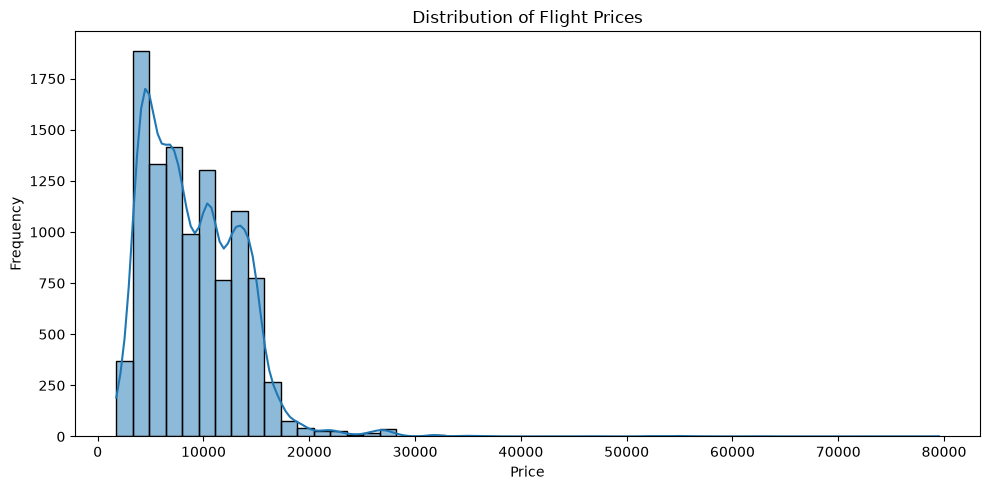

In [42]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=final_df,
    x="Price",
    bins=50,
    kde=True
)

plt.title("Distribution of Flight Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [43]:
Q1 = final_df["Price"].quantile(0.25)
Q3 = final_df["Price"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = final_df[
    (final_df["Price"] < lower_bound) |
    (final_df["Price"] > upper_bound)
]

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Potential outlier count:", len(outliers))
print("Potential outlier percentage:",
      round(len(outliers) / len(final_df) * 100, 2), "%")


Q1: 5224.0
Q3: 12344.75
IQR: 7120.75
Lower bound: -5457.125
Upper bound: 23025.875
Potential outlier count: 94
Potential outlier percentage: 0.9 %


In [44]:
high_fares = final_df.nlargest(15, "Price")

high_fares[
    [
        "Airline",
        "Source",
        "Destination",
        "Route",
        "Total_Stops",
        "Duration_Minutes",
        "Additional_Info",
        "Price"
    ]
]

,Airline,Source,Destination,Route,Total_Stops,Duration_Minutes,Additional_Info,Price
2924,Jet Airways Business,Banglore,New Delhi,BLR → BOM → DEL,1,340,business class,79512
5372,Jet Airways Business,Banglore,New Delhi,BLR → BOM → DEL,1,400,business class,62427
10364,Jet Airways Business,Banglore,New Delhi,BLR → MAA → DEL,1,280,business class,57209
1478,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1,365,no info,54826
2618,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1,375,no info,54826
5439,Jet Airways,Banglore,New Delhi,BLR → BOM → DEL,1,365,no info,54826
9715,Jet Airways Business,Delhi,Cochin,DEL → ATQ → BOM → COK,2,500,no info,52285
657,Jet Airways Business,Banglore,New Delhi,BLR → BOM → DEL,1,300,no info,52229
7351,Jet Airways Business,Delhi,Cochin,DEL → ATQ → BOM → COK,2,500,no info,46490
396,Multiple carriers,Delhi,Cochin,DEL → BOM → COK,1,385,no info,36983


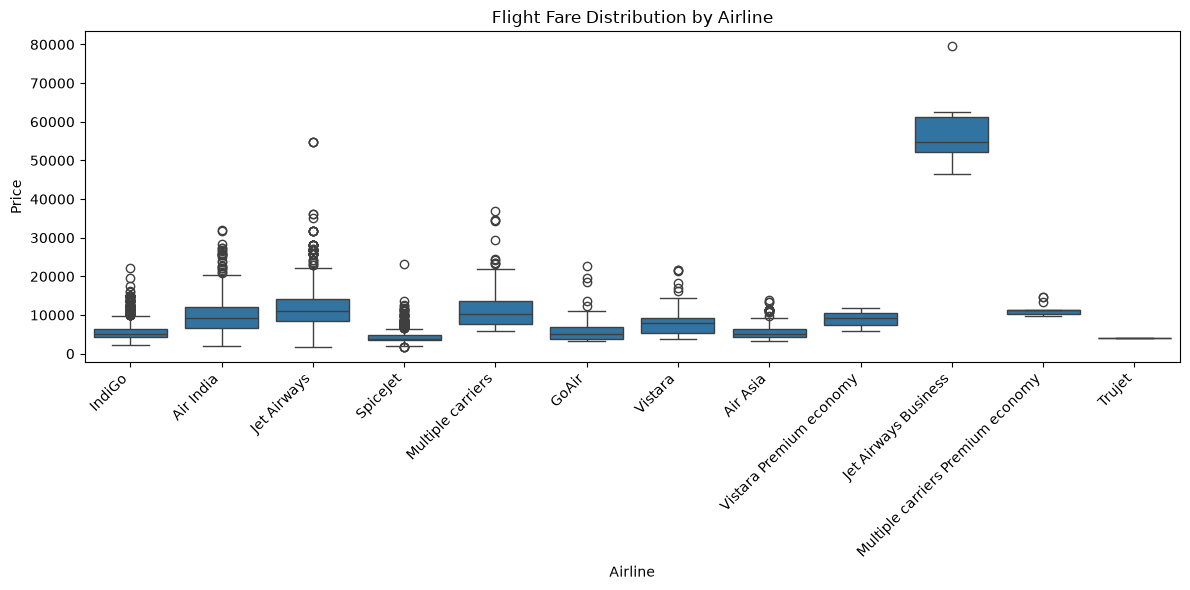

In [45]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=final_df,
    x="Airline",
    y="Price"
)

plt.title("Flight Fare Distribution by Airline")
plt.xlabel("Airline")
plt.ylabel("Price")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


In [46]:
airline_fares = (
    final_df.groupby("Airline")["Price"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_values("median", ascending=False)
)

airline_fares


,count,median,mean,min,max
Airline,,,,,
Jet Airways Business,6,54747.0,58358.666667,46490,79512
Multiple carriers Premium economy,13,11269.0,11418.846154,9845,14629
Jet Airways,3700,11134.0,11599.021081,1840,54826
Multiple carriers,1196,10197.0,10902.678094,5797,36983
Air India,1694,9316.0,9556.608028,2050,31945
Vistara Premium economy,3,9125.0,8962.333333,5969,11793
Vistara,478,7980.0,7801.355649,3687,21730
Air Asia,319,5162.0,5590.260188,3383,13774
GoAir,194,5135.0,5861.056701,3398,22794


In [47]:
stops_fares = (
    final_df.groupby("Total_Stops")["Price"]
    .agg(["count", "median", "mean", "min", "max"])
    .sort_index()
)

stops_fares


,count,median,mean,min,max
Total_Stops,,,,,
0,3475,4667.0,5018.506763,1759,31945
1,5625,10262.0,10594.123556,3480,79512
2,1318,12723.0,12761.099393,4647,52285
3,43,13007.0,13260.674419,8607,21829
4,1,17686.0,17686.000000,17686,17686


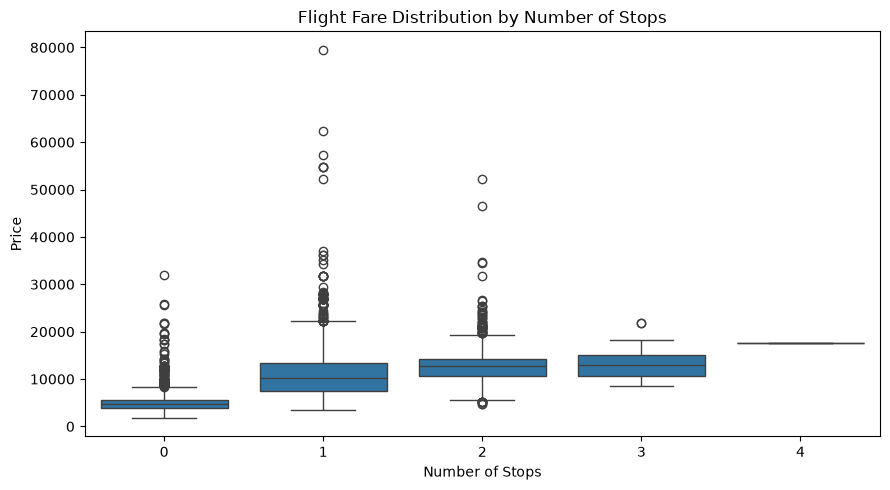

In [48]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=final_df,
    x="Total_Stops",
    y="Price"
)

plt.title("Flight Fare Distribution by Number of Stops")
plt.xlabel("Number of Stops")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


               count  median          mean
Journey_Month                             
3               2678  9769.0  10695.397311
4               1078  5073.0   5766.545455
5               3395  8662.0   9029.239764
6               3311  8510.0   8736.152522


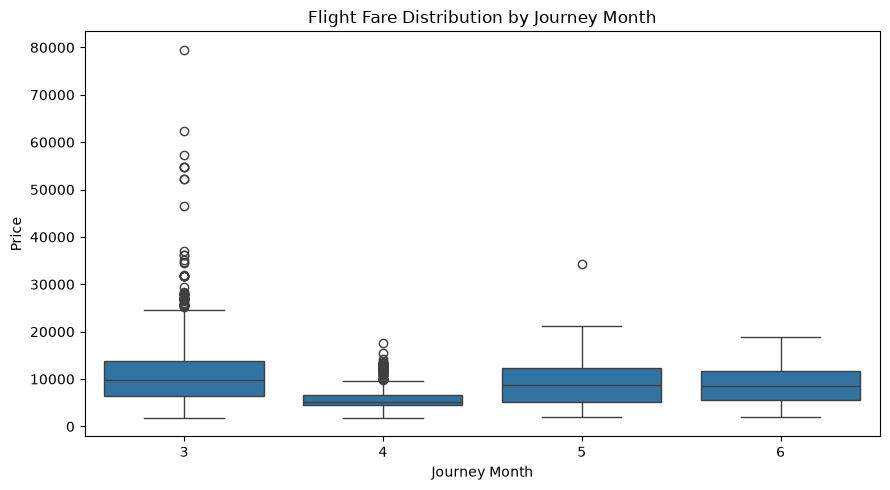

In [49]:
monthly_fares = (
    final_df.groupby("Journey_Month")["Price"]
    .agg(["count", "median", "mean"])
    .sort_index()
)

print(monthly_fares)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=final_df,
    x="Journey_Month",
    y="Price"
)

plt.title("Flight Fare Distribution by Journey Month")
plt.xlabel("Journey Month")
plt.ylabel("Price")
plt.tight_layout()
plt.show()


In [50]:
print("Flights by source:")
print(final_df["Source"].value_counts())

print("\nFlights by destination:")
print(final_df["Destination"].value_counts())

Flights by source:
Source
Delhi       4345
Kolkata     2860
Banglore    2179
Mumbai       697
Chennai      381
Name: count, dtype: int64

Flights by destination:
Destination
Cochin       4345
Banglore     2860
Delhi        1265
New Delhi     914
Hyderabad     697
Kolkata       381
Name: count, dtype: int64


In [51]:
source_fares = (
    final_df.groupby("Source")["Price"]
    .agg(["count", "median", "mean"])
    .sort_values("median", ascending=False)
)

source_fares

,count,median,mean
Source,,,
Delhi,4345,10262.0,10461.600690
Kolkata,2860,9345.0,9143.083566
Banglore,2179,6121.0,8022.872877
Chennai,381,3850.0,4789.892388
Mumbai,697,3342.0,5059.708752


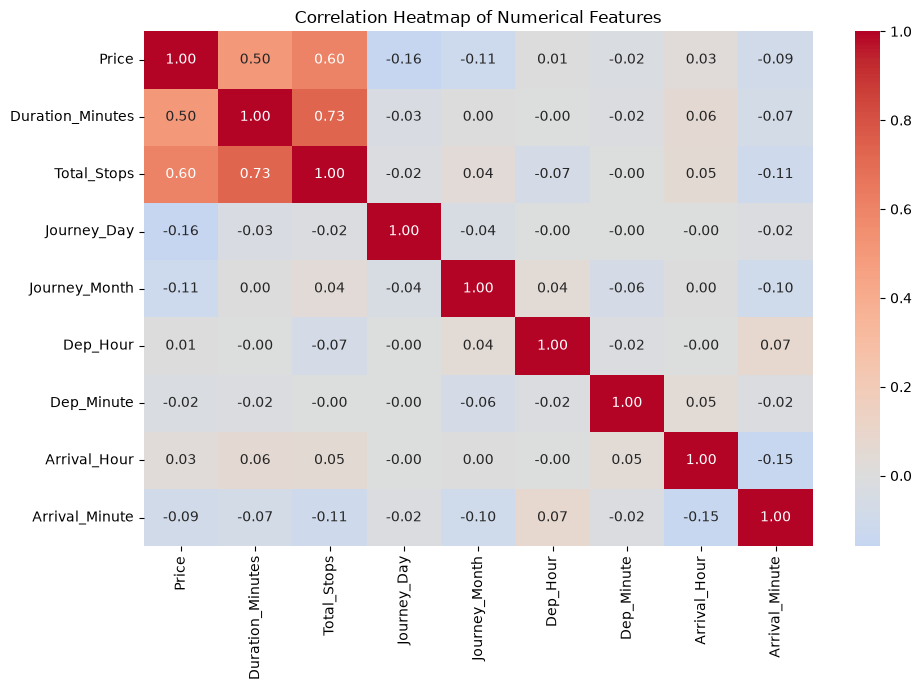

In [52]:
numeric_features = [
    "Price",
    "Duration_Minutes",
    "Total_Stops",
    "Journey_Day",
    "Journey_Month",
    "Dep_Hour",
    "Dep_Minute",
    "Arrival_Hour",
    "Arrival_Minute"
]

correlation = final_df[numeric_features].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()


In [53]:
final_df.columns.tolist()

['Airline',
 'Date_of_Journey',
 'Source',
 'Destination',
 'Route',
 'Dep_Time',
 'Arrival_Time',
 'Duration',
 'Total_Stops',
 'Additional_Info',
 'Price',
 'Duration_Minutes',
 'Journey_Day',
 'Journey_Month',
 'Dep_Hour',
 'Dep_Minute',
 'Arrival_Hour',
 'Arrival_Minute',
 'Route_Stops_Count']

In [54]:
y = final_df["Price"]

feature_columns = [
    "Airline",
    "Source",
    "Destination",
    "Total_Stops",
    "Duration_Minutes",
    "Journey_Day",
    "Journey_Month",
    "Dep_Hour",
    "Dep_Minute",
    "Arrival_Hour",
    "Arrival_Minute",
    "Additional_Info"
]

X = final_df[feature_columns].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())


Feature matrix shape: (10462, 12)
Target shape: (10462,)

Feature columns:
['Airline', 'Source', 'Destination', 'Total_Stops', 'Duration_Minutes', 'Journey_Day', 'Journey_Month', 'Dep_Hour', 'Dep_Minute', 'Arrival_Hour', 'Arrival_Minute', 'Additional_Info']

Missing values in X: 0
Missing values in y: 0


In [55]:
from sklearn.model_selection import train_test_split

In [56]:
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.2, random_state=42)

In [57]:
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((8369, 12), (2093, 12), (8369,), (2093,))

In [58]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

categorical_features = [
    "Airline",
    "Source",
    "Destination",
    "Additional_Info"
]

numerical_features = [
    "Total_Stops",
    "Duration_Minutes",
    "Journey_Day",
    "Journey_Month",
    "Dep_Hour",
    "Dep_Minute",
    "Arrival_Hour",
    "Arrival_Minute"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessor created successfully.")


Preprocessor created successfully.


In [59]:
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

print("Linear Regression pipeline created successfully.")


Linear Regression pipeline created successfully.


In [60]:
linear_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](12,)","['Airline','Source','Destination',...,'Arrival_Hour','Arrival_Minute', 'Additional_Info']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,12
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically pa

In [61]:
y_pred = linear_model.predict(X_test)

print("First 10 actual fares:")
print(y_test.head(10).tolist())

print("\nFirst 10 predicted fares:")
print(y_pred[:10].round(2).tolist())


First 10 actual fares:
[17996, 3873, 4462, 2228, 4991, 7670, 14086, 6386, 6628, 6934]

First 10 predicted fares:
[15950.09, 4745.73, 4891.47, 5272.28, 2659.24, 10750.63, 8938.94, 7054.79, 8035.88, 5920.66]


In [62]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"MAE:  ₹{mae:.2f}")
print(f"RMSE: ₹{rmse:.2f}")
print(f"R²:   {r2:.4f}")


MAE:  ₹1773.06
RMSE: ₹2656.29
R²:   0.6616


In [63]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print(f"Random Forest MAE:  ₹{rf_mae:.2f}")
print(f"Random Forest RMSE: ₹{rf_rmse:.2f}")
print(f"Random Forest R²:   {rf_r2:.4f}")


Random Forest MAE:  ₹676.97
Random Forest RMSE: ₹1499.80
Random Forest R²:   0.8921


In [64]:
from sklearn.metrics import mean_absolute_error, r2_score

train_pred = rf_model.predict(X_train)
test_pred = rf_model.predict(X_test)

print("Training MAE:", round(mean_absolute_error(y_train, train_pred), 2))
print("Testing MAE: ", round(mean_absolute_error(y_test, test_pred), 2))

print("Training R²:", round(r2_score(y_train, train_pred), 4))
print("Testing R²: ", round(r2_score(y_test, test_pred), 4))


Training MAE: 268.51
Testing MAE:  676.97
Training R²: 0.9822
Testing R²:  0.8921


In [65]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_depth15 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        n_jobs=-1
    ))
])

rf_depth15.fit(X_train, y_train)

train_pred_15 = rf_depth15.predict(X_train)
test_pred_15 = rf_depth15.predict(X_test)

print("Training MAE:", round(mean_absolute_error(y_train, train_pred_15), 2))
print("Testing MAE: ", round(mean_absolute_error(y_test, test_pred_15), 2))
print("Training R²:", round(r2_score(y_train, train_pred_15), 4))
print("Testing R²: ", round(r2_score(y_test, test_pred_15), 4))


Training MAE: 376.31
Testing MAE:  702.88
Training R²: 0.9749
Testing R²:  0.8932


In [66]:
rf_leaf5 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=-1
    ))
])

rf_leaf5.fit(X_train, y_train)

train_pred_leaf5 = rf_leaf5.predict(X_train)
test_pred_leaf5 = rf_leaf5.predict(X_test)

print("Training MAE:", round(mean_absolute_error(y_train, train_pred_leaf5), 2))
print("Testing MAE: ", round(mean_absolute_error(y_test, test_pred_leaf5), 2))
print("Training R²:", round(r2_score(y_train, train_pred_leaf5), 4))
print("Testing R²: ", round(r2_score(y_test, test_pred_leaf5), 4))


Training MAE: 602.93
Testing MAE:  777.28
Training R²: 0.9049
Testing R²:  0.8733


In [67]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline


cv = KFold(n_splits=5, shuffle=True, random_state=42)

configs = {
    "Original": {},
    "Depth 15": {"max_depth": 15},
    "Leaf 5": {"min_samples_leaf": 5},
    "Depth 20": {"max_depth": 20},
}

for name, params in configs.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
            **params
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    mae_scores = -scores

    print(
        f"{name}: Mean CV MAE = ₹{mae_scores.mean():.2f}, "
        f"Std = ₹{mae_scores.std():.2f}"
    )


Original: Mean CV MAE = ₹708.90, Std = ₹13.77
Depth 15: Mean CV MAE = ₹732.37, Std = ₹8.61
Leaf 5: Mean CV MAE = ₹828.57, Std = ₹16.21
Depth 20: Mean CV MAE = ₹708.45, Std = ₹12.08


In [68]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

final_pred = rf_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_pred)
final_rmse = np.sqrt(mean_squared_error(y_test, final_pred))
final_r2 = r2_score(y_test, final_pred)

print(f"Final Test MAE:  ₹{final_mae:.2f}")
print(f"Final Test RMSE: ₹{final_rmse:.2f}")
print(f"Final Test R²:   {final_r2:.4f}")


Final Test MAE:  ₹676.97
Final Test RMSE: ₹1499.80
Final Test R²:   0.8921


In [69]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X_test.columns,
    "Importance": perm_result.importances_mean,
    "Std": perm_result.importances_std
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print(importance_df)


             Feature   Importance        Std
0            Airline  1843.413864  52.644691
1   Duration_Minutes  1798.468161  10.015798
2      Journey_Month   775.320476  28.525564
3    Additional_Info   649.122745  15.105078
4        Journey_Day   600.873191  42.481284
5        Total_Stops   448.031699  16.549083
6        Destination   320.971579   6.730403
7             Source   221.087357   9.403732
8         Dep_Minute   213.367910   7.008701
9       Arrival_Hour   200.505438  11.314187
10          Dep_Hour   157.769869   8.288840
11    Arrival_Minute   153.363129   9.041419


In [70]:
print("Additional_Info categories:")
print(final_df["Additional_Info"].value_counts())

print("\nAverage and median fare by Additional_Info:")
print(
    final_df.groupby("Additional_Info")["Price"]
    .agg(["count", "mean", "median", "min", "max"])
    .sort_values("median", ascending=False)
)


Additional_Info categories:
Additional_Info
no info                         8185
in-flight meal not included     1926
no check-in baggage included     318
1 long layover                    19
change airports                    7
business class                     4
1 short layover                    1
red-eye flight                     1
2 long layover                     1
Name: count, dtype: int64

Average and median fare by Additional_Info:
                              count          mean   median    min    max
Additional_Info                                                         
business class                    4  56811.250000  59818.0  28097  79512
1 short layover                   1  26743.000000  26743.0  26743  26743
2 long layover                    1  26480.000000  26480.0  26480  26480
1 long layover                   19  22109.631579  25735.0   7744  31825
change airports                   7  16800.714286  15119.0  13366  26092
red-eye flight                    1  1087

In [71]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


features_without_info = [
    col for col in feature_columns
    if col != "Additional_Info"
]

categorical_no_info = ["Airline", "Source", "Destination"]

numerical_features = [
    "Total_Stops", "Duration_Minutes", "Journey_Day", "Journey_Month",
    "Dep_Hour", "Dep_Minute", "Arrival_Hour", "Arrival_Minute"
]

preprocessor_no_info = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_no_info),
        ("numerical", "passthrough", numerical_features)
    ]
)

rf_no_info = Pipeline(steps=[
    ("preprocessor", preprocessor_no_info),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

rf_no_info.fit(X_train[features_without_info], y_train)

# Evaluate on the same test set
pred_no_info = rf_no_info.predict(X_test[features_without_info])

print("Without Additional_Info")
print(f"MAE:  ₹{mean_absolute_error(y_test, pred_no_info):.2f}")
print(f"RMSE: ₹{np.sqrt(mean_squared_error(y_test, pred_no_info)):.2f}")
print(f"R²:   {r2_score(y_test, pred_no_info):.4f}")


Without Additional_Info
MAE:  ₹1172.27
RMSE: ₹1968.42
R²:   0.8142


In [72]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

extra_trees_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_model.fit(X_train, y_train)

extra_pred = extra_trees_model.predict(X_test)

print(f"Extra Trees MAE:  ₹{mean_absolute_error(y_test, extra_pred):.2f}")
print(f"Extra Trees RMSE: ₹{np.sqrt(mean_squared_error(y_test, extra_pred)):.2f}")
print(f"Extra Trees R²:   {r2_score(y_test, extra_pred):.4f}")


Extra Trees MAE:  ₹643.17
Extra Trees RMSE: ₹1509.57
Extra Trees R²:   0.8907


In [73]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.pipeline import Pipeline
import numpy as np

cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

for name, regressor in models.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", regressor)
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    mae_scores = -scores

    print(
        f"{name}: Mean CV MAE = ₹{mae_scores.mean():.2f}, "
        f"Std = ₹{mae_scores.std():.2f}"
    )


Random Forest: Mean CV MAE = ₹708.90, Std = ₹13.77
Extra Trees: Mean CV MAE = ₹663.33, Std = ₹17.14


In [74]:
from sklearn.metrics import mean_absolute_error, r2_score

extra_train_pred = extra_trees_model.predict(X_train)
extra_test_pred = extra_trees_model.predict(X_test)

print("Training MAE:", round(mean_absolute_error(y_train, extra_train_pred), 2))
print("Testing MAE: ", round(mean_absolute_error(y_test, extra_test_pred), 2))

print("Training R²:", round(r2_score(y_train, extra_train_pred), 4))
print("Testing R²: ", round(r2_score(y_test, extra_test_pred), 4))


Training MAE: 39.74
Testing MAE:  643.17
Training R²: 0.9961
Testing R²:  0.8907


In [75]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


extra_trees_depth20 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=100,
        max_depth=20,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_depth20.fit(X_train, y_train)

train_pred_depth20 = extra_trees_depth20.predict(X_train)
test_pred_depth20 = extra_trees_depth20.predict(X_test)

print("Training MAE:", round(mean_absolute_error(y_train, train_pred_depth20), 2))
print("Testing MAE: ", round(mean_absolute_error(y_test, test_pred_depth20), 2))
print("Training R²:", round(r2_score(y_train, train_pred_depth20), 4))
print("Testing R²: ", round(r2_score(y_test, test_pred_depth20), 4))


Training MAE: 77.88
Testing MAE:  639.64
Training R²: 0.9955
Testing R²:  0.8949


In [76]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline


cv = KFold(n_splits=5, shuffle=True, random_state=42)

extra_configs = {
    "Original Extra Trees": {},
    "Extra Trees depth 20": {"max_depth": 20}
}

for name, params in extra_configs.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", ExtraTreesRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
            **params
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    mae_scores = -scores

    print(
        f"{name}: Mean CV MAE = ₹{mae_scores.mean():.2f}, "
        f"Std = ₹{mae_scores.std():.2f}"
    )


Original Extra Trees: Mean CV MAE = ₹663.33, Std = ₹17.14
Extra Trees depth 20: Mean CV MAE = ₹665.00, Std = ₹11.12


In [77]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

extra_trees_leaf2 = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=100,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

extra_trees_leaf2.fit(X_train, y_train)

train_pred_leaf2 = extra_trees_leaf2.predict(X_train)
test_pred_leaf2 = extra_trees_leaf2.predict(X_test)

print("Training MAE:", round(mean_absolute_error(y_train, train_pred_leaf2), 2))
print("Testing MAE: ", round(mean_absolute_error(y_test, test_pred_leaf2), 2))
print("Training R²:", round(r2_score(y_train, train_pred_leaf2), 4))
print("Testing R²: ", round(r2_score(y_test, test_pred_leaf2), 4))


Training MAE: 300.08
Testing MAE:  648.45
Training R²: 0.9773
Testing R²:  0.8969


In [78]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline

cv = KFold(n_splits=5, shuffle=True, random_state=42)

extra_configs = {
    "Original": {},
    "Depth 20": {"max_depth": 20},
    "Leaf 2": {"min_samples_leaf": 2}
}

for name, params in extra_configs.items():
    model = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("regressor", ExtraTreesRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1,
            **params
        ))
    ])

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="neg_mean_absolute_error",
        n_jobs=1
    )

    mae_scores = -scores

    print(
        f"{name}: Mean CV MAE = ₹{mae_scores.mean():.2f}, "
        f"Std = ₹{mae_scores.std():.2f}"
    )


Original: Mean CV MAE = ₹663.33, Std = ₹17.14
Depth 20: Mean CV MAE = ₹665.00, Std = ₹11.12
Leaf 2: Mean CV MAE = ₹679.24, Std = ₹15.31


In [79]:
import pandas as pd

model_comparison = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Test MAE": 1773.06,
        "Test RMSE": 2656.29,
        "Test R2": 0.6616,
        "Mean CV MAE": None
    },
    {
        "Model": "Random Forest",
        "Test MAE": 676.97,
        "Test RMSE": 1499.80,
        "Test R2": 0.8921,
        "Mean CV MAE": 708.90
    },
    {
        "Model": "Extra Trees - Original",
        "Test MAE": 643.17,
        "Test RMSE": 1509.57,
        "Test R2": 0.8907,
        "Mean CV MAE": 663.33
    },
    {
        "Model": "Extra Trees - Depth 20",
        "Test MAE": 639.64,
        "Test RMSE": None,
        "Test R2": 0.8949,
        "Mean CV MAE": 665.00
    },
    {
        "Model": "Extra Trees - Leaf 2",
        "Test MAE": 648.45,
        "Test RMSE": None,
        "Test R2": 0.8969,
        "Mean CV MAE": 679.24
    }
])

print(model_comparison.to_string(index=False))


                 Model  Test MAE  Test RMSE  Test R2  Mean CV MAE
     Linear Regression   1773.06    2656.29   0.6616          NaN
         Random Forest    676.97    1499.80   0.8921       708.90
Extra Trees - Original    643.17    1509.57   0.8907       663.33
Extra Trees - Depth 20    639.64        NaN   0.8949       665.00
  Extra Trees - Leaf 2    648.45        NaN   0.8969       679.24


In [80]:
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.pipeline import Pipeline

final_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", ExtraTreesRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

final_model.fit(X_train, y_train)

print("Final candidate model trained successfully!")


Final candidate model trained successfully!


In [81]:
import joblib

joblib.dump(final_model, "flight_fare_model.pkl")

print("Flight Fare model saved successfully!")


Flight Fare model saved successfully!


In [82]:

import os

model_path = "flight_fare_model.pkl"

print("File exists:", os.path.exists(model_path))
print("File size:", round(os.path.getsize(model_path) / 1024, 2), "KB")


File exists: True
File size: 70865.6 KB


In [83]:
import joblib

loaded_model = joblib.load("flight_fare_model.pkl")

print("Saved model loaded successfully!")
print(type(loaded_model))


Saved model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [84]:
sample_input = X_test.iloc[[0]]

actual_price = y_test.iloc[0]

predicted_price = loaded_model.predict(sample_input)[0]

print(f"Actual Flight Fare:    ₹{actual_price:.2f}")
print(f"Predicted Flight Fare: ₹{predicted_price:.2f}")
print(f"Absolute Error:        ₹{abs(actual_price - predicted_price):.2f}")


Actual Flight Fare:    ₹17996.00
Predicted Flight Fare: ₹14907.66
Absolute Error:        ₹3088.34


In [85]:
for col in ["Airline", "Source", "Destination", "Additional_Info"]:
    print(f"\n{col}:")
    print(sorted(X_train[col].unique()))


Airline:
['Air Asia', 'Air India', 'GoAir', 'IndiGo', 'Jet Airways', 'Jet Airways Business', 'Multiple carriers', 'Multiple carriers Premium economy', 'SpiceJet', 'Trujet', 'Vistara', 'Vistara Premium economy']

Source:
['Banglore', 'Chennai', 'Delhi', 'Kolkata', 'Mumbai']

Destination:
['Banglore', 'Cochin', 'Delhi', 'Hyderabad', 'Kolkata', 'New Delhi']

Additional_Info:
['1 long layover', '1 short layover', '2 long layover', 'business class', 'change airports', 'in-flight meal not included', 'no check-in baggage included', 'no info', 'red-eye flight']
